In [94]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [95]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_models import build_model, apply_prior
from crafts_stack.halo_fitting import halofit
from astropy.stats import sigma_clip

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

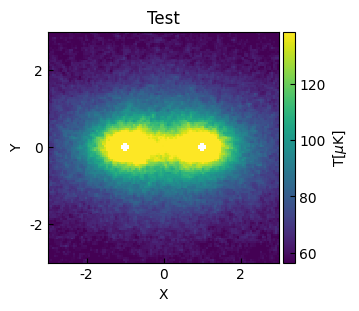

In [96]:
data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
# data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

data = sigma_clip(data, sigma=10, masked=True)
plot_heatmap(data, title='Test')

In [97]:
coord = get_coord()
model = build_model('nfw', 'const', param_bg=dict(amplitude=60))
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Const2D(amplitude=60.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... r_s_1 ellipticity_1 theta_1 amplitude_2
    ----------- -------- -------- ----- ... ----- ------------- ------- -----------
           50.0     -1.0      0.0   0.5 ...   0.5           0.0     0.0        60.0


In [98]:
tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    'ellipticity_0': (0, 0.5),
    'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

# init_bg = {
#     "degree": 2
# }

model = apply_prior(model, bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Const2D(amplitude=60.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... r_s_1 ellipticity_1 theta_1 amplitude_2
    ----------- -------- -------- ----- ... ----- ------------- ------- -----------
           50.0     -1.0      0.0   0.5 ...   0.5           0.0     0.0        60.0


# without mask

In [99]:
data_list, fit_model, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=49.46093419, x_mean=-1., y_mean=0., r_s=0.50137767, ellipticity=0., theta=-0.01107952)>

    [1]: <NFW2D(amplitude=49.46093419, x_mean=1., y_mean=0., r_s=0.501329, ellipticity=0., theta=-0.01107952)>

    [2]: <Const2D(amplitude=59.98970274)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...        theta_1           amplitude_2    
    ----------------- -------- -------- ... --------------------- ------------------
    49.46093418639116     -1.0      0.0 ... -0.011079517268605737 59.989702743931346

Goodness of fit:
Chi-squared: 10134060.781
Reduced chi-squared: 704.390
RMS residual: 26.551



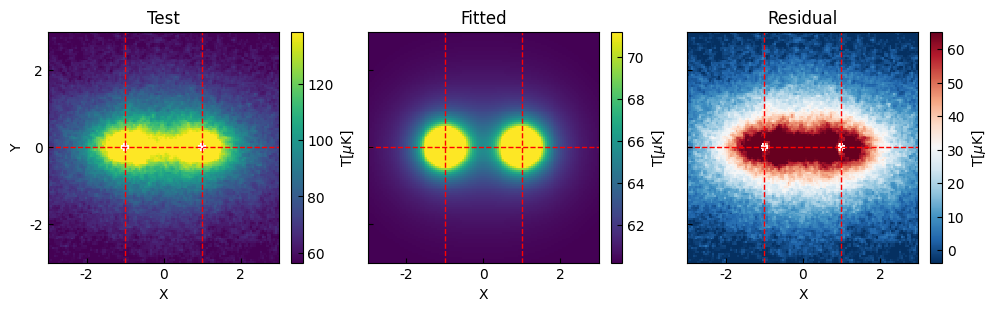

In [100]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
# axes =  plot_stack_fit_res(data_list, title=title, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

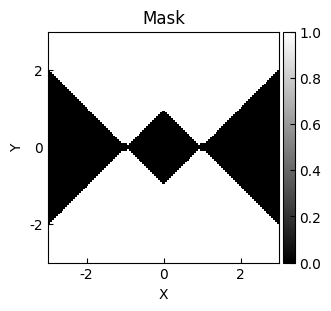

In [101]:
# mask_sector = get_mask_sector(coord=coord)
mask_sector = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask_sector = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask_sector, title='Mask', cmap='gray', cbar_label='')

In [102]:
data_list_sector, fit_model, fit_info  = halofit(coord, data, model=model, mask=mask_sector, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=0.43696797, x_mean=-1., y_mean=0., r_s=120.50581613, ellipticity=0.5, theta=-59.71369567)>

    [1]: <NFW2D(amplitude=0.43696797, x_mean=1., y_mean=0., r_s=119.22334936, ellipticity=0.5, theta=-3.15598911)>

    [2]: <Const2D(amplitude=43.11089639)>
Parameters:
        amplitude_0     x_mean_0 y_mean_0 ...      theta_1          amplitude_2   
    ------------------- -------- -------- ... ------------------ -----------------
    0.43696797168697815     -1.0      0.0 ... -3.155989110786605 43.11089639118098

Goodness of fit:
Chi-squared: 227801.974
Reduced chi-squared: 22.042
RMS residual: 4.692



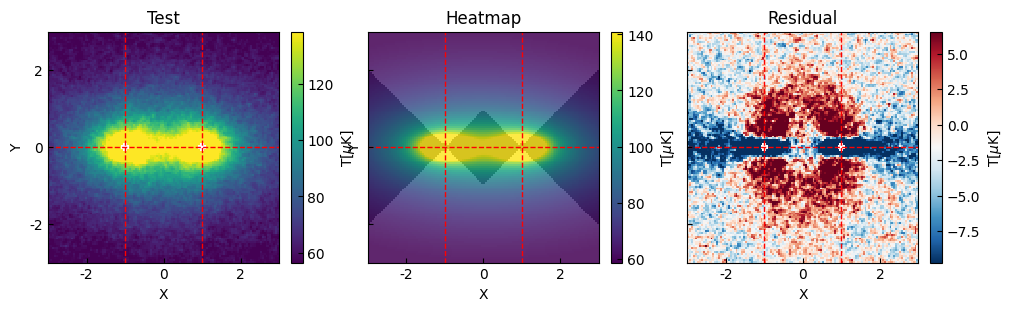

In [103]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask_sector)
# axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask_sector, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

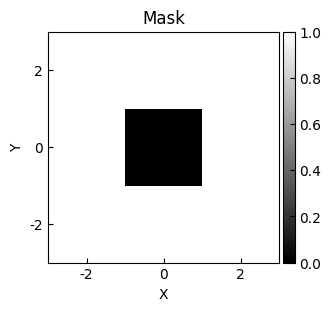

In [104]:
# mask_sq = ~get_mask_square(coord=coord)
mask_sq = ~get_mask_square(coord=coord, xlim=[-1, 1], ylim=[-1, 1])

plot_heatmap(mask_sq, title='Mask', cmap='gray', cbar_label='')

In [105]:
data_list_square, fit_model, fit_info  = halofit(coord, data, model=model, mask=mask_sq, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=49.46572613, x_mean=-1., y_mean=0., r_s=0.5075059, ellipticity=0., theta=-0.0110205)>

    [1]: <NFW2D(amplitude=49.46572613, x_mean=1., y_mean=0., r_s=0.50729543, ellipticity=0., theta=-0.0110205)>

    [2]: <Const2D(amplitude=59.9902638)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...        theta_1           amplitude_2   
    ----------------- -------- -------- ... --------------------- -----------------
    49.46572612556039     -1.0      0.0 ... -0.011020496921418738 59.99026379796925

Goodness of fit:
Chi-squared: 4659525.195
Reduced chi-squared: 364.395
RMS residual: 19.088



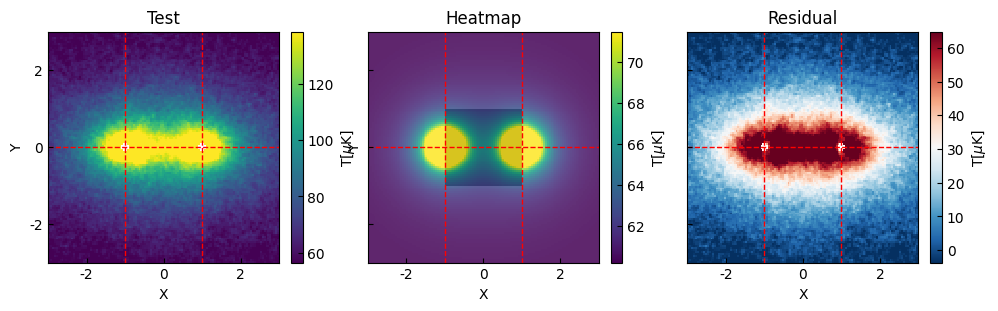

In [106]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq)
# axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [107]:
from mytools.plot import plot_hist

(-100.0, 100.0)

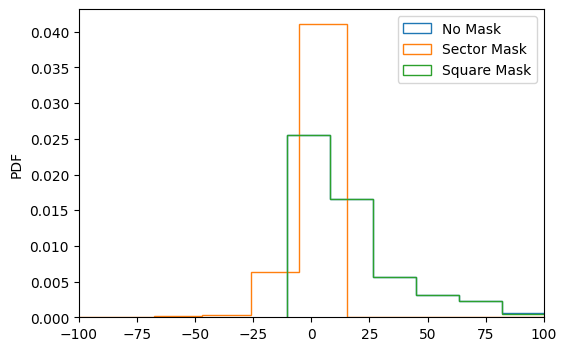

In [108]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
ax = plot_hist(res_list, label=labels, bins=100)
ax.set_xlim(-100, 100)

# profiles

In [109]:
from mytools.plot import plot_line_diff, make_figure, plt, set_ticks

In [117]:
# stack_fit_res = data_list
stack_fit_res = data_list_sector
# stack_fit_res = data_list_square

In [118]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'X=1']

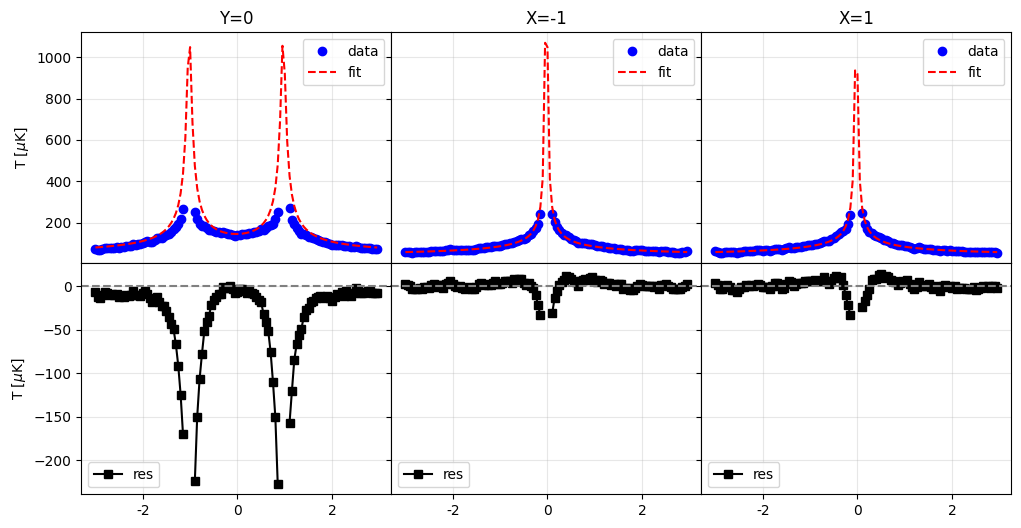

In [119]:
fig, axes = make_figure(2,3, figsize=(12,6), wspace=0., hspace=0.,aspect=None,sharex=True, sharey='row')

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

axes[0,0].set_ylabel(r'T [$\mu$K]')
axes[1,0].set_ylabel(r'T [$\mu$K]')
set_ticks(axes[1,0], share=False)


# estimate signal level

In [120]:

from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(0.33632325585043377), np.float64(0.0), np.float64(0.75), np.float64(1.2957958627909811)]
Gauss fit covariance: 
[[ 0.49583873 -0.3496663  -0.09199962]
 [-0.3496663   4.04217991 -0.48134395]
 [-0.09199962 -0.48134395  0.14717662]]
4 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 947.583
Reduced chi-squared: 8.099
RMS residual: 2.810

width: 0.75
width_pix: 15


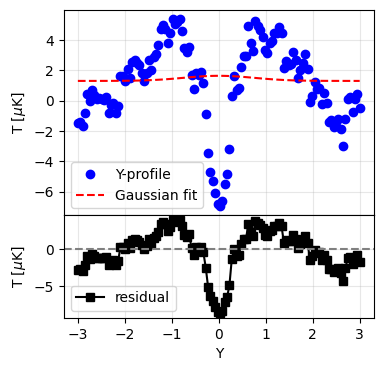

In [121]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.1, 0.75),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=3, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

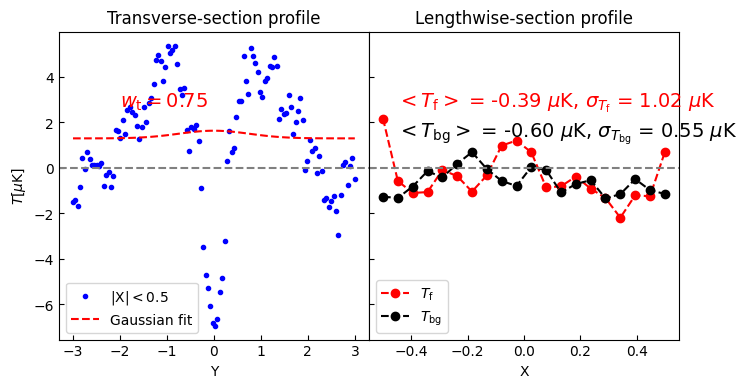

In [122]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

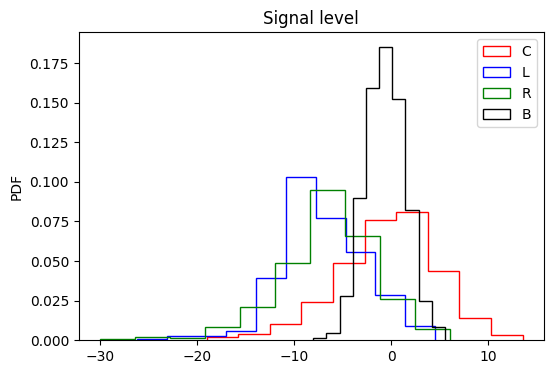

In [123]:
plot_hist(clrb, label=['C','L','R','B'], color=['r', 'b','g','k'], title='Signal level')